# Experiment 1: PILOT V02 and Three Comparators
Four methods: **PILOT V02 (Oct29)**, **PILOT Original (Oct21)**, **UniFP Original**, and **Pos**. Selection uses recorded checkpoint identities, not evaluation directory names. No FiLM oscillation analysis, simulation, training, or modified-policy evaluation.

In [1]:
import os, json, sys, importlib
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebooks/pilot_v02_comparison.py").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
import pilot_v02_comparison as cohort
cohort = importlib.reload(cohort)
CONFIG = cohort.defaults(ROOT)
# Edit roots/output or individual method run_name/checkpoint_sha256 selectors here.
# Both PILOT entries intentionally have native task b1z1_pact, but distinct IDs.
CONFIG["methods"]


{'unifp': {'task': 'b1z1_unifp_original',
  'display_name': 'UniFP',
  'run_name': 'Oct23_15-25-20_upstream_architecture'},
 'pos': {'task': 'b1z1_ppo_pos',
  'display_name': 'Pos',
  'run_name': 'Oct23_16-58-40_position_only'},
 'pilot_original': {'task': 'b1z1_pact',
  'display_name': 'PILOT (Original)',
  'run_name': 'Oct21_00-46-21_b1z1_pact_improved',
  'film_v02': False},
 'pilot_v02': {'task': 'b1z1_pact',
  'display_name': 'PILOT V02',
  'run_name': 'Oct29_15-14-37_b1z1_pact_improved',
  'film_v02': True}}

In [2]:
CONFIG.update({
    "load_range": "in",  # Exp1: analyze OOD separately.
    "motion": "combined",  # Also export the existing separate motion-mode table.
    "loading": ["loaded", "unloaded"],  # Exp2: never pool these conditions.
    "comparison_loading": "loaded",
    "acceleration_metrics": True,
    "rmse_bootstrap_resamples": 10000,
    "rmse_confidence_level": 0.95,
    "rmse_resampling_seed": 0,
    "reuse_summaries": True,
    # Times New Roman when installed; all sizes in points.
    "figure_title_font_size": 12, "title_font_size": 11,
    "axis_label_font_size": 10, "tick_font_size": 9,
    "legend_font_size": 9, "annotation_font_size": 8,
})
# Optional JSON file for unattended execution; does not modify old notebooks.
if os.environ.get("PILOT_COMPARISON_CONFIG"):
    CONFIG.update(json.loads(Path(os.environ["PILOT_COMPARISON_CONFIG"]).read_text()))
methods, recordings, inventory = cohort.resolve_cohorts(CONFIG, 1)
display(pd.DataFrame(inventory))


,method,task,checkpoint_sha256,recordings,evaluation_seeds,training_seeds,status
0,unifp,b1z1_unifp_original,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,9,"[0, 1, 2]",[],available
1,pos,b1z1_ppo_pos,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,9,"[0, 1, 2]",[],available
2,pilot_original,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,9,"[0, 1, 2]",[],available
3,pilot_v02,b1z1_pact,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,9,"[0, 1, 2]",[],available


## Native Metrics and Exports
Run the existing summarizer separately for each checkpoint. Errors use finite pre-failure samples; S_track includes zero-credit failed tails. Physical limits pool valid joint-substep counts within each seed. Existing units, recovery windows/dwell, histogram frames, and equal-seed aggregation remain unchanged. All outputs go to `analysis/pilot_v02_comparison`, never the old analysis folders.

In [3]:
summaries, inventory, confidence = cohort.summarize_tasks(CONFIG, 1)
for method, summary in summaries.items():
    print(summary["display_name"])
    display(pd.DataFrame(summary["aggregates"]))
    print("\n".join(summary["diagnostics"]) or "No coverage diagnostics.")


Exp1: UniFP (9 recordings)


/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/notebooks/pilot_v02_comparison.py:142: RuntimeWarning: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
  summary=engine.summarize(settings)


Exp1: Pos (9 recordings)


/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/notebooks/pilot_v02_comparison.py:142: RuntimeWarning: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
  summary=engine.summarize(settings)


Exp1: PILOT (Original) (9 recordings)


/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/notebooks/pilot_v02_comparison.py:142: RuntimeWarning: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
  summary=engine.summarize(settings)


... (7 outputs left out)

,condition,load_range,motion,metric,unit,mean,sd,contributing_seeds,attempted_trials,contributing_trials
0,combined-disturbance,in,combined,ee_error_m,m,0.053892,0.000441,3,300,300.0
1,combined-disturbance,in,combined,planar_velocity_error_m_s,m/s,0.081110,0.001906,3,300,300.0
2,combined-disturbance,in,combined,yaw_error_rad_s,rad/s,0.111316,0.001775,3,300,300.0
3,combined-disturbance,in,combined,S_track,fraction,0.787209,0.014197,3,300,300.0
4,combined-disturbance,in,combined,failure_rate,fraction,0.003333,0.005774,3,300,300.0
...,...,...,...,...,...,...,...,...,...,...
157,nominal,in,stationary,recovery_fraction,fraction,NaN,NaN,0,150,NaN
158,nominal,in,stationary,recovery_fraction_ee,fraction,NaN,NaN,0,150,NaN
159,nominal,in,stationary,recovery_fraction_velocity,fraction,NaN,NaN,0,150,NaN
160,nominal,in,stationary,torso_angular_acceleration_rms,rad/s^2,7.461505,0.017808,3,150,NaN


Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
PILOT V02


,condition,load_range,motion,metric,unit,mean,sd,contributing_seeds,attempted_trials,contributing_trials
0,combined-disturbance,in,combined,ee_error_m,m,0.053529,0.000634,3,300,300.0
1,combined-disturbance,in,combined,planar_velocity_error_m_s,m/s,0.055382,0.000498,3,300,300.0
2,combined-disturbance,in,combined,yaw_error_rad_s,rad/s,0.079445,0.000741,3,300,300.0
3,combined-disturbance,in,combined,S_track,fraction,0.886360,0.001102,3,300,300.0
4,combined-disturbance,in,combined,failure_rate,fraction,0.010000,0.010000,3,300,300.0
...,...,...,...,...,...,...,...,...,...,...
157,nominal,in,stationary,recovery_fraction,fraction,NaN,NaN,0,150,NaN
158,nominal,in,stationary,recovery_fraction_ee,fraction,NaN,NaN,0,150,NaN
159,nominal,in,stationary,recovery_fraction_velocity,fraction,NaN,NaN,0,150,NaN
160,nominal,in,stationary,torso_angular_acceleration_rms,rad/s^2,4.399224,0.007238,3,150,NaN


Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.


## Existing Comparison Tables and Figures
All four methods appear in the main and focused tables and figures. Protocol and seed-coverage checks are unchanged. CSV/LaTeX and PDF/PNG exports are retained.

main


nominal                                                \
                         EE [m] Velocity [m/s]    Yaw [rad/s]    Tracking [%]   
UniFP             0.030 ± 0.000  0.038 ± 0.001  0.064 ± 0.001  98.946 ± 0.028   
Pos               0.025 ± 0.000  0.044 ± 0.000  0.066 ± 0.000  98.849 ± 0.019   
PILOT (Original)  0.022 ± 0.000  0.052 ± 0.001  0.065 ± 0.000  98.871 ± 0.026   
PILOT V02         0.033 ± 0.000  0.033 ± 0.000  0.055 ± 0.000  99.122 ± 0.017   

                                ee-disturbance                                \
                    Failure [%]         EE [m] Velocity [m/s]    Yaw [rad/s]   
UniFP             0.000 ± 0.000  0.072 ± 0.002  0.057 ± 0.000  0.087 ± 0.000   
Pos               0.000 ± 0.000  0.064 ± 0.001  0.056 ± 0.001  0.080 ± 0.001   
PILOT (Original)  0.000 ± 0.000  0.054 ± 0.001  0.067 ± 0.000  0.105 ± 0.001   
PILOT V02         0.000 ± 0.000  0.053 ± 0.001  0.048 ± 0.000  0.074 ± 0.000   

                                                combined-disturbance  \
                    Tracking [%]    Failure [%]               EE [m]   
UniFP             76.949 ± 1.704  7.667 ± 3.055        0.072 ± 0.001   
Pos               79.120 ± 1.428  0.667 ± 0.577        0.064 ± 0.002   
PILOT (Original)  82.445 ± 0.576  0.333 ± 0.577        0.054 ± 0.000   
PILOT V02         89.562 ± 0.477  0.667 ± 0.577        0.054 ± 0.001   

                                                                               
                 Velocity [m/s]    Yaw [rad/s]    Tracking [%]    Failure [%]  
UniFP             0.063 ± 0.001  0.091 ± 0.001  76.818 ± 1.079  6.000 ± 2.646  
Pos               0.064 ± 0.001  0.086 ± 0.000  77.163 ± 1.297  1.667 ± 0.577  
PILOT (Original)  0.081 ± 0.002  0.111 ± 0.002  78.721 ± 1.420  0.333 ± 0.577  
PILOT V02         0.055 ± 0.000  0.079 ± 0.001  88.636 ± 0.110  1.000 ± 1.000

motion_modes


Mean EE position error [m] ↓  \
Motion                       Method                                          
Stationary manipulation      UniFP                           0.068 ± 0.003   
                             Pos                             0.058 ± 0.004   
                             PILOT (Original)                0.056 ± 0.002   
                             PILOT V02                       0.053 ± 0.002   
Locomotion with manipulation UniFP                           0.075 ± 0.001   
                             Pos                             0.070 ± 0.003   
                             PILOT (Original)                0.052 ± 0.002   
                             PILOT V02                       0.054 ± 0.002   

                                              Planar velocity error [m/s] ↓  \
Motion                       Method                                           
Stationary manipulation      UniFP                            0.044 ± 0.001   
                             Pos                              0.035 ± 0.001   
                             PILOT (Original)                 0.047 ± 0.001   
                             PILOT V02                        0.037 ± 0.002   
Locomotion with manipulation UniFP                            0.083 ± 0.002   
                             Pos                              0.093 ± 0.001   
                             PILOT (Original)                 0.115 ± 0.003   
                             PILOT V02                        0.073 ± 0.001   

                                              Yaw-rate error [rad/s] ↓  \
Motion                       Method                                      
Stationary manipulation      UniFP                       0.071 ± 0.002   
                             Pos                         0.062 ± 0.001   
                             PILOT (Original)            0.079 ± 0.001   
                             PILOT V02                   0.061 ± 0.001   
Locomotion with manipulation UniFP                       0.110 ± 0.004   
                             Pos                         0.111 ± 0.002   
                             PILOT (Original)            0.143 ± 0.003   
                             PILOT V02                   0.098 ± 0.002   

                                                S_track [%] ↑  \
Motion                       Method                             
Stationary manipulation      UniFP             77.690 ± 1.281   
                             Pos               82.956 ± 2.778   
                             PILOT (Original)  83.976 ± 1.221   
                             PILOT V02         89.260 ± 0.628   
Locomotion with manipulation UniFP             75.946 ± 0.882   
                             Pos               71.370 ± 0.185   
                             PILOT (Original)  73.466 ± 2.208   
                             PILOT V02         88.012 ± 0.824   

                                              Velocity S_track [%] ↑  \
Motion                       Method                                    
Stationary manipulation      UniFP                    93.364 ± 0.492   
                             Pos                      97.917 ± 0.742   
                             PILOT (Original)         96.622 ± 0.236   
                             PILOT V02                97.953 ± 0.533   
Locomotion with manipulation UniFP                    88.479 ± 2.168   
                             Pos                      88.865 ± 0.469   
                             PILOT (Original)         78.715 ± 2.166   
                             PILOT V02                93.387 ± 0.527   

                                              Manipulation S_track [%] ↑  \
Motion                       Method                                        
Stationary manipulation      UniFP                        77.930 ± 1.248   
                             Pos                          83.024 ± 2.790   
                             PILOT (Original)            

physical_limits


Saturation [%]   Position [%]  \
Method           Condition                                            
UniFP            nominal               0.018 ± 0.001  0.000 ± 0.000   
                 ee-disturbance        0.030 ± 0.001  0.096 ± 0.022   
                 combined-disturbance  0.031 ± 0.002  0.095 ± 0.016   
Pos              nominal               0.000 ± 0.000  0.000 ± 0.000   
                 ee-disturbance        0.005 ± 0.001  0.108 ± 0.026   
                 combined-disturbance  0.007 ± 0.007  0.102 ± 0.026   
PILOT (Original) nominal               0.000 ± 0.000  0.000 ± 0.000   
                 ee-disturbance        0.030 ± 0.004  0.088 ± 0.019   
                 combined-disturbance  0.030 ± 0.005  0.089 ± 0.008   
PILOT V02        nominal               0.000 ± 0.000  0.000 ± 0.000   
                 ee-disturbance        0.021 ± 0.007  0.087 ± 0.007   
                 combined-disturbance  0.021 ± 0.006  0.093 ± 0.010   

                                        Velocity [%]  
Method           Condition                            
UniFP            nominal               0.000 ± 0.000  
                 ee-disturbance        0.000 ± 0.000  
                 combined-disturbance  0.000 ± 0.000  
Pos              nominal               0.000 ± 0.000  
                 ee-disturbance        0.000 ± 0.000  
                 combined-disturbance  0.000 ± 0.000  
PILOT (Original) nominal               0.000 ± 0.000  
                 ee-disturbance        0.000 ± 0.000  
                 combined-disturbance  0.000 ± 0.000  
PILOT V02        nominal               0.000 ± 0.000  
                 ee-disturbance        0.000 ± 0.000  
                 combined-disturbance  0.000 ± 0.000

disturbance_response


Peak EE [m]   Recovery [s]  \
Method           Condition                                            
UniFP            ee-disturbance        0.277 ± 0.001  0.679 ± 0.011   
                 combined-disturbance  0.278 ± 0.002  0.699 ± 0.006   
Pos              ee-disturbance        0.160 ± 0.006  0.318 ± 0.009   
                 combined-disturbance  0.160 ± 0.004  0.322 ± 0.008   
PILOT (Original) ee-disturbance        0.148 ± 0.000  0.394 ± 0.028   
                 combined-disturbance  0.149 ± 0.001  0.399 ± 0.045   
PILOT V02        ee-disturbance        0.156 ± 0.001  0.332 ± 0.015   
                 combined-disturbance  0.158 ± 0.001  0.361 ± 0.020   

                                        Recovered [%] EE recovered [%]  \
Method           Condition                                               
UniFP            ee-disturbance        75.333 ± 2.848   77.111 ± 2.694   
                 combined-disturbance  75.333 ± 1.202   77.778 ± 1.503   
Pos              ee-disturbance        75.444 ± 1.347   76.889 ± 1.018   
                 combined-disturbance  71.111 ± 1.540   75.000 ± 0.882   
PILOT (Original) ee-disturbance        74.667 ± 1.453   82.222 ± 1.711   
                 combined-disturbance  68.111 ± 2.341   81.000 ± 1.202   
PILOT V02        ee-disturbance        88.667 ± 1.732   89.444 ± 1.711   
                 combined-disturbance  86.111 ± 1.388   89.000 ± 0.667   

                                      Velocity recovered [%]  
Method           Condition                                    
UniFP            ee-disturbance               88.667 ± 2.333  
                 combined-disturbance         87.778 ± 1.953  
Pos              ee-disturbance               97.111 ± 0.839  
                 combined-disturbance         90.556 ± 1.388  
PILOT (Original) ee-disturbance               87.778 ± 0.770  
                 combined-disturbance         81.000 ± 2.404  
PILOT V02        ee-disturbance               97.111 ± 0.694  
                 combined-disturbance         94.889 ± 0.694

optional_metrics


torso_angular_acceleration_rms [rad/s^2]  \
Method           Condition                                                       
UniFP            nominal                                         9.703 ± 0.075   
                 ee-disturbance                                 10.524 ± 0.092   
                 combined-disturbance                           10.641 ± 0.119   
Pos              nominal                                        11.045 ± 0.106   
                 ee-disturbance                                 11.437 ± 0.069   
                 combined-disturbance                           11.545 ± 0.080   
PILOT (Original) nominal                                        10.366 ± 0.041   
                 ee-disturbance                                 11.278 ± 0.086   
                 combined-disturbance                           11.411 ± 0.112   
PILOT V02        nominal                                         7.696 ± 0.015   
                 ee-disturbance                                  8.928 ± 0.074   
                 combined-disturbance                            9.060 ± 0.023   

                                      ee_linear_acceleration_rms [m/s^2]  
Method           Condition                                                
UniFP            nominal                                   8.157 ± 0.048  
                 ee-disturbance                           10.852 ± 0.270  
                 combined-disturbance                     10.780 ± 0.247  
Pos              nominal                                   7.313 ± 0.031  
                 ee-disturbance                            8.794 ± 0.137  
                 combined-disturbance                      8.840 ± 0.136  
PILOT (Original) nominal                                  11.558 ± 0.021  
                 ee-disturbance                           13.548 ± 0.106  
                 combined-disturbance                     13.593 ± 0.080  
PILOT V02        nominal                                  10.546 ± 0.006  
                 ee-disturbance                           13.125 ± 0.133  
                 combined-disturbance                     13.158 ± 0.108

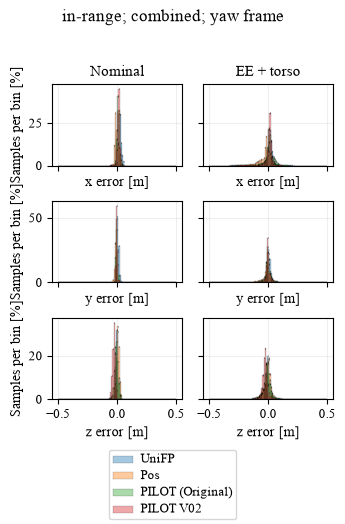

pilot_original: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
pilot_v02: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
pos: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
unifp: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.


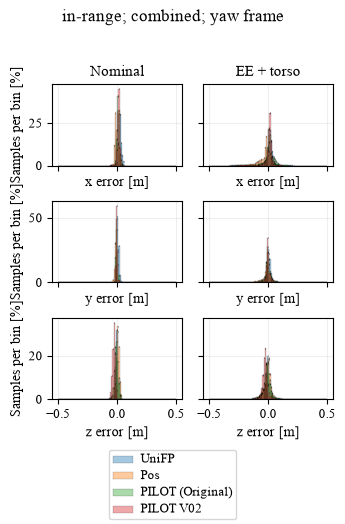

In [4]:
import exp1_analysis as engine
engine = importlib.reload(engine)
COMPARE = cohort.comparison_config(CONFIG, summaries, 1)
tables, figure, diagnostics = engine.compare(COMPARE)
for name, table in tables.items():
    print(name)
    display(table)
display(figure)
print("\n".join(diagnostics) or "Compatible protocols and coverage.")


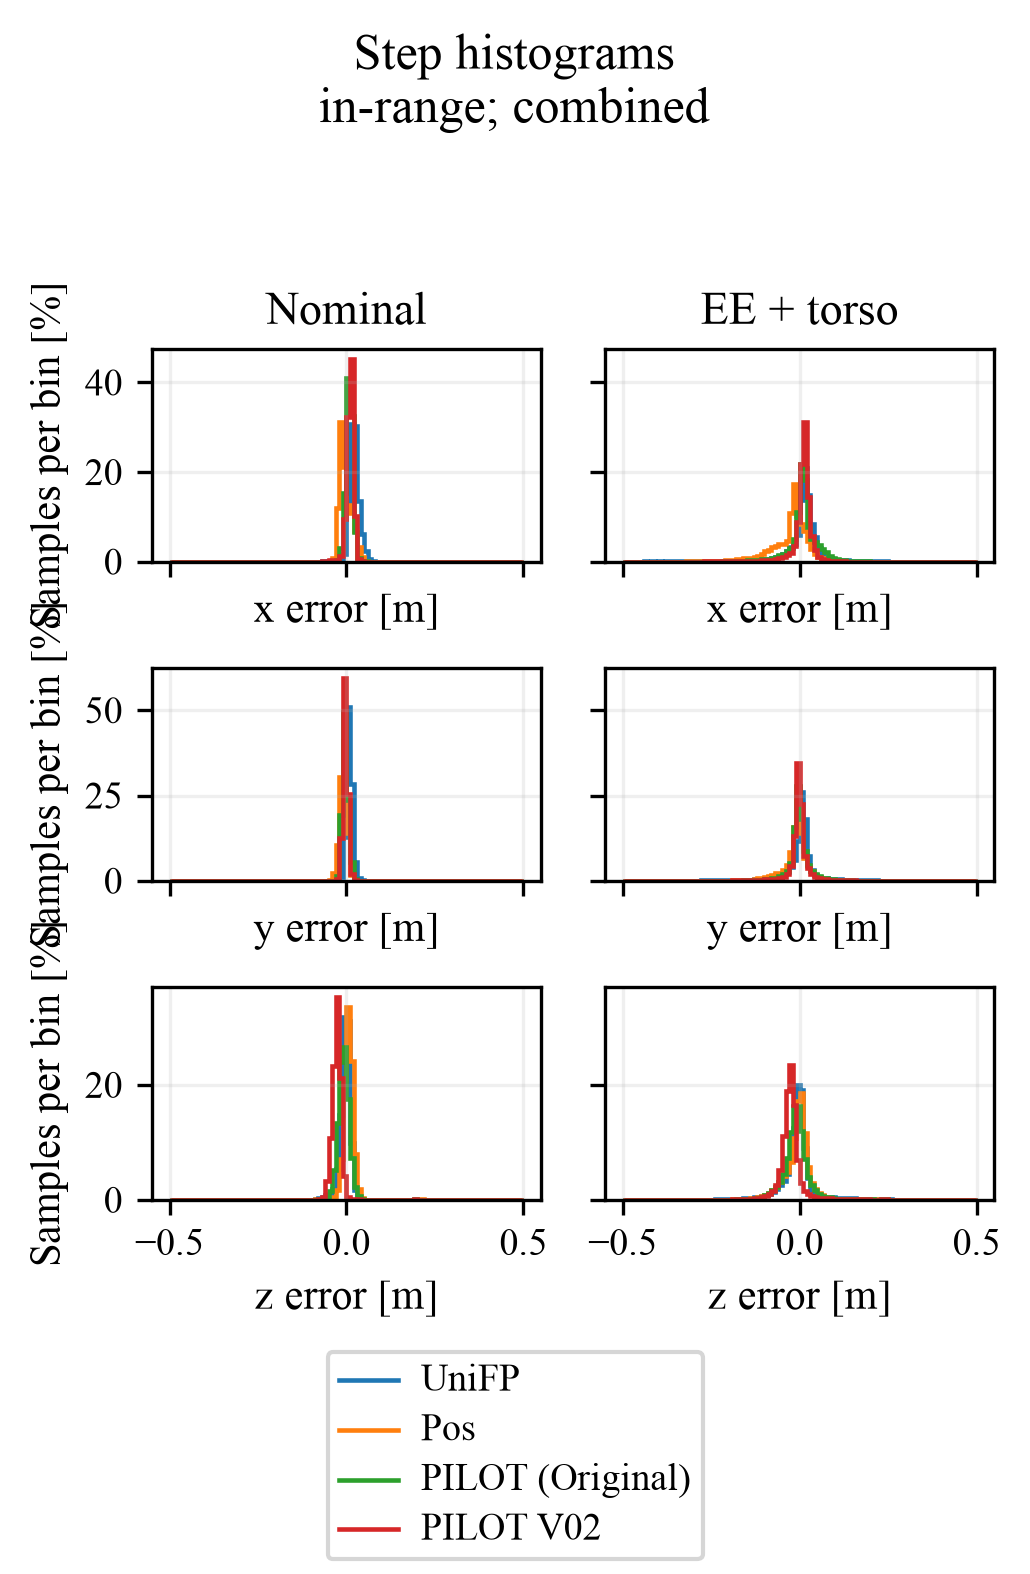

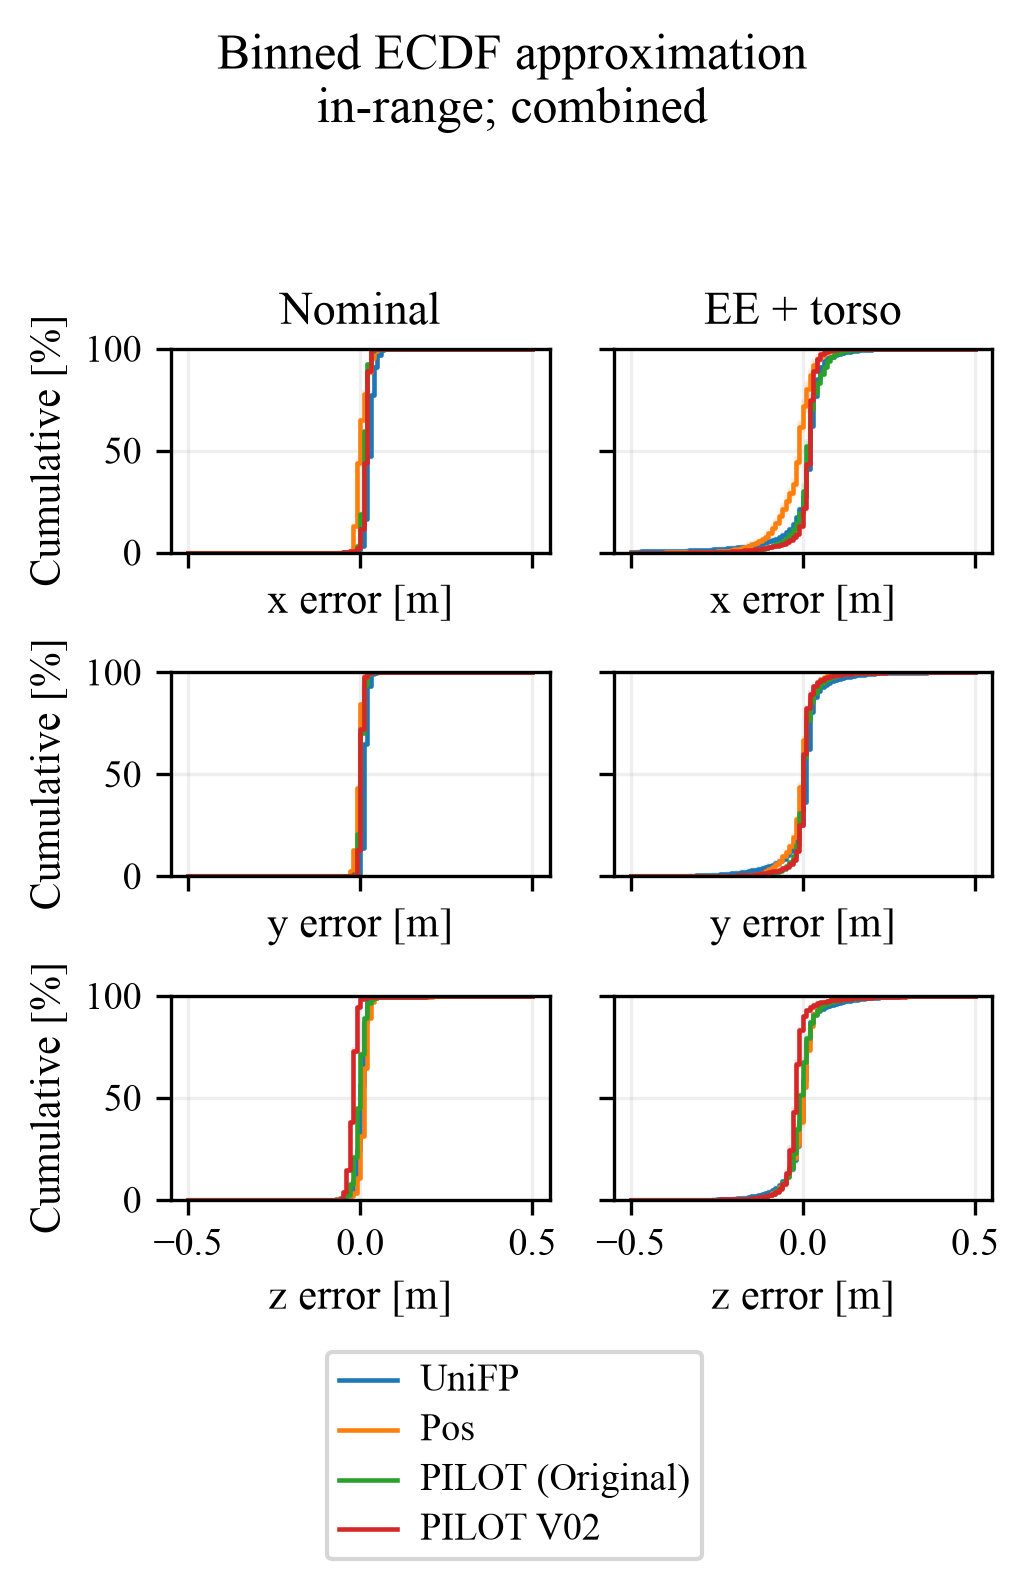

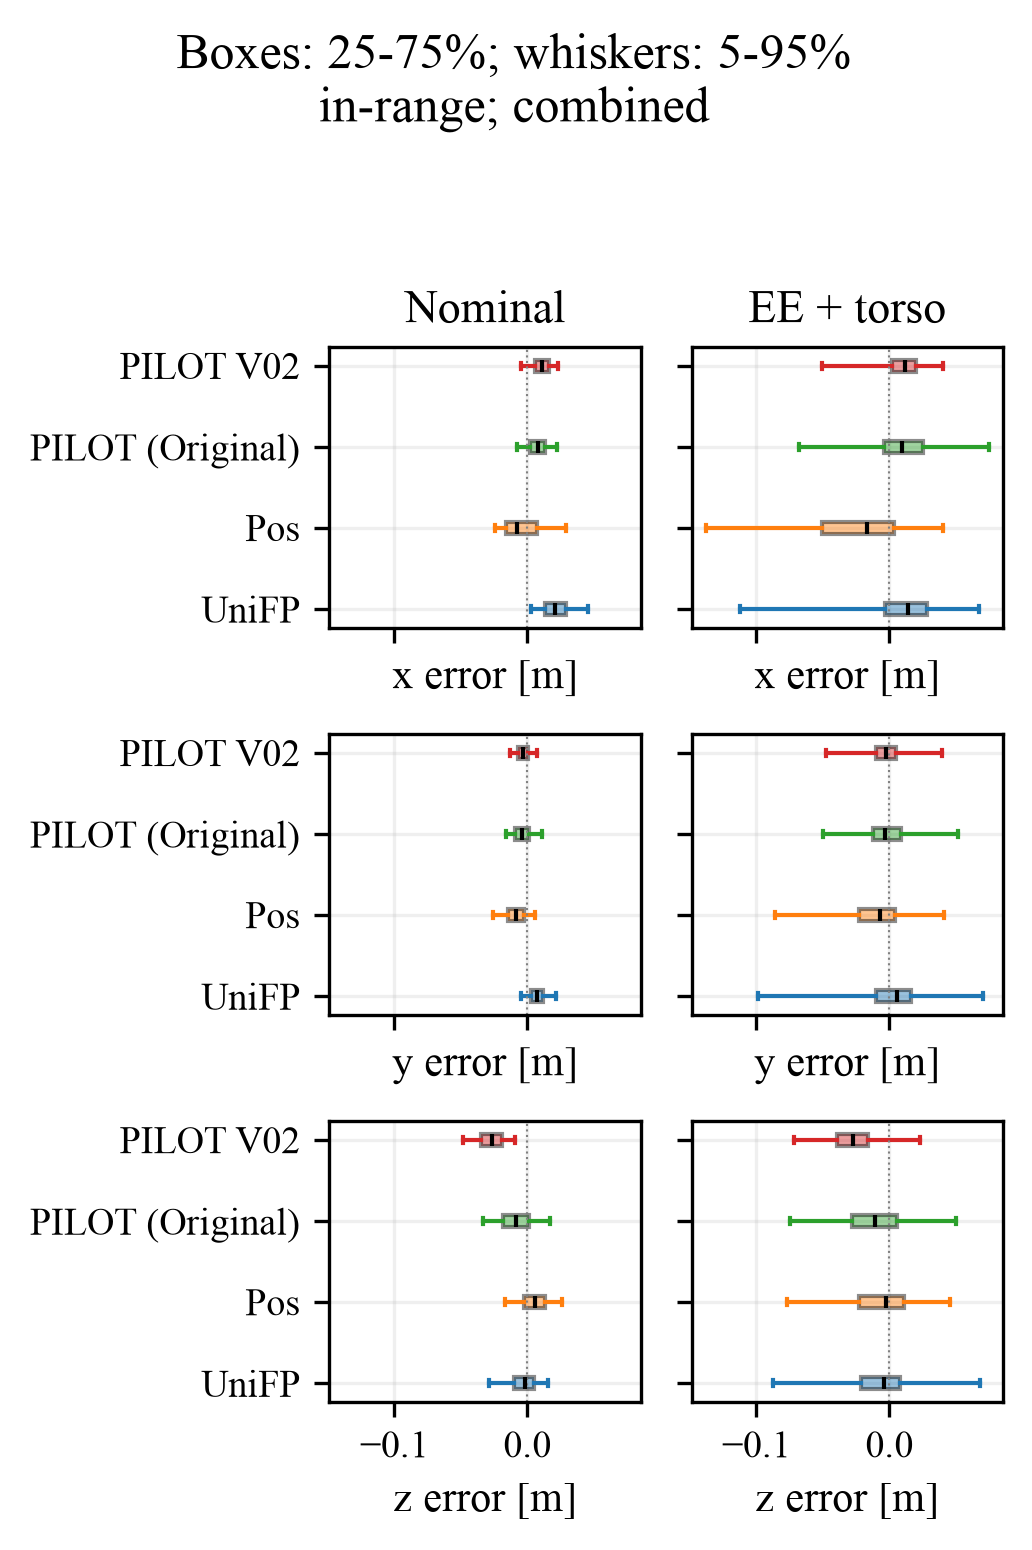

In [5]:
for kind in COMPARE["additional_plots"]:
    display(Image(filename=str(Path(COMPARE["output_dir"]) / f"ee_{kind}.png")))


## Confidence Intervals
Dedicated CSVs report **V02 minus comparator** in native units (tracking fractions remain fractions; physical-limit percentages remain percentages). Broad metric CIs bootstrap paired **evaluation-seed summaries**, preserving the original trial weighting, pooled limit denominators, recovery censoring, and stage definitions. They are pointwise, exploratory fixed-checkpoint intervals, not independent-training uncertainty; three seeds give limited precision. Missing metrics stay unavailable. Distribution plots remain descriptive, not additional significance tests.

In [6]:
display(confidence)
print("Dedicated CIs:", Path(CONFIG["output_dir"]) / "exp1/exp1_metric_confidence_intervals.csv")
print("Tables and figures:", COMPARE["output_dir"])


,stage,metric,unit,condition,load_range,motion,reference_method,comparator_method,reference_checkpoint,comparator_checkpoint,...,comparator_available_seeds,confidence_level,bootstrap_resamples,resampling_unit,status,reference_mean,comparator_mean,difference,ci_low,ci_high
0,all,S_track,fraction,combined-disturbance,in,combined,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,...,3,0.95,10000,paired evaluation seed,available,0.886360,0.768178,0.118182,0.106120,0.129613
1,all,S_track,fraction,combined-disturbance,in,combined,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,...,3,0.95,10000,paired evaluation seed,available,0.886360,0.771631,0.114729,0.104853,0.130840
2,all,S_track,fraction,combined-disturbance,in,combined,pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,...,3,0.95,10000,paired evaluation seed,available,0.886360,0.787209,0.099151,0.082640,0.110360
3,all,S_track,fraction,combined-disturbance,in,locomotion,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,...,3,0.95,10000,paired evaluation seed,available,0.880116,0.759458,0.120658,0.102987,0.136853
4,all,S_track,fraction,combined-disturbance,in,locomotion,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,...,3,0.95,10000,paired evaluation seed,available,0.880116,0.713698,0.166418,0.159813,0.172720
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,all,yaw_error_rad_s,rad/s,nominal,in,locomotion,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,...,3,0.95,10000,paired evaluation seed,available,0.069204,0.083147,-0.013943,-0.013990,-0.013913
482,all,yaw_error_rad_s,rad/s,nominal,in,locomotion,pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,...,3,0.95,10000,paired evaluation seed,available,0.069204,0.076434,-0.007231,-0.007605,-0.006766
483,all,yaw_error_rad_s,rad/s,nominal,in,stationary,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,...,3,0.95,10000,paired evaluation seed,available,0.041667,0.045192,-0.003525,-0.003924,-0.003040
484,all,yaw_error_rad_s,rad/s,nominal,in,stationary,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,...,3,0.95,10000,paired evaluation seed,available,0.041667,0.048993,-0.007326,-0.007556,-0.007207


Dedicated CIs: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/pilot_v02_comparison/exp1/exp1_metric_confidence_intervals.csv
Tables and figures: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/pilot_v02_comparison/exp1/comparison
